# Load Thomas BreathMetrics features and exclusions

The active features are now `/breathmetrics/windows`. Original pressure and timestamps remain intact. Previous calculated features are archived under `/legacy_candidate_features`; previous `/respiration/candidate_breaths` and `candidate_rate_hz` are also legacy.

**Eligibility is automated screening, not completed manual QC.** 10.2 is on hold. Windows overlapping 11.2's approximate 482-516 s signal-loss interval are held out. Other windows must pass the documented count and near-flat rules; retained windows are not automatically human-approved. Check required features for missing values before modeling.

Use the existing H5 files beside this notebook. No MATLAB or BreathMetrics installation is required to load exported results. Dependencies: numpy, pandas, h5py, matplotlib. Raw pressure is uncalibrated; phase polarity and BORIS alignment remain unverified.


## Updated cycle detector: start here

Green markers now use local peak prominence instead of the Thomas block-wide peak/trough threshold and alternating-extrema selection. This is a separate candidate detector, not validated BreathMetrics features. Default prominence is max(15 ADC, 12% of the local one-second 90th–10th percentile span); minimum peak spacing is 40 ms. These provisional settings may require adjustment for sensor gain/noise and are not biological sniff criteria.

The same settings are shown for 11.3, 10.3, and 11.2. The known 11.2 dropout is explicitly masked, not rescued by peak detection. Synthetic tests verify drift/amplitude tolerance, flat-signal rejection, and no intervals across gaps. Visible-cycle agreement still requires review; unrecognized signal loss may generate false candidates. H5 features remain unchanged until this detector is validated. No time points were removed or shifted.


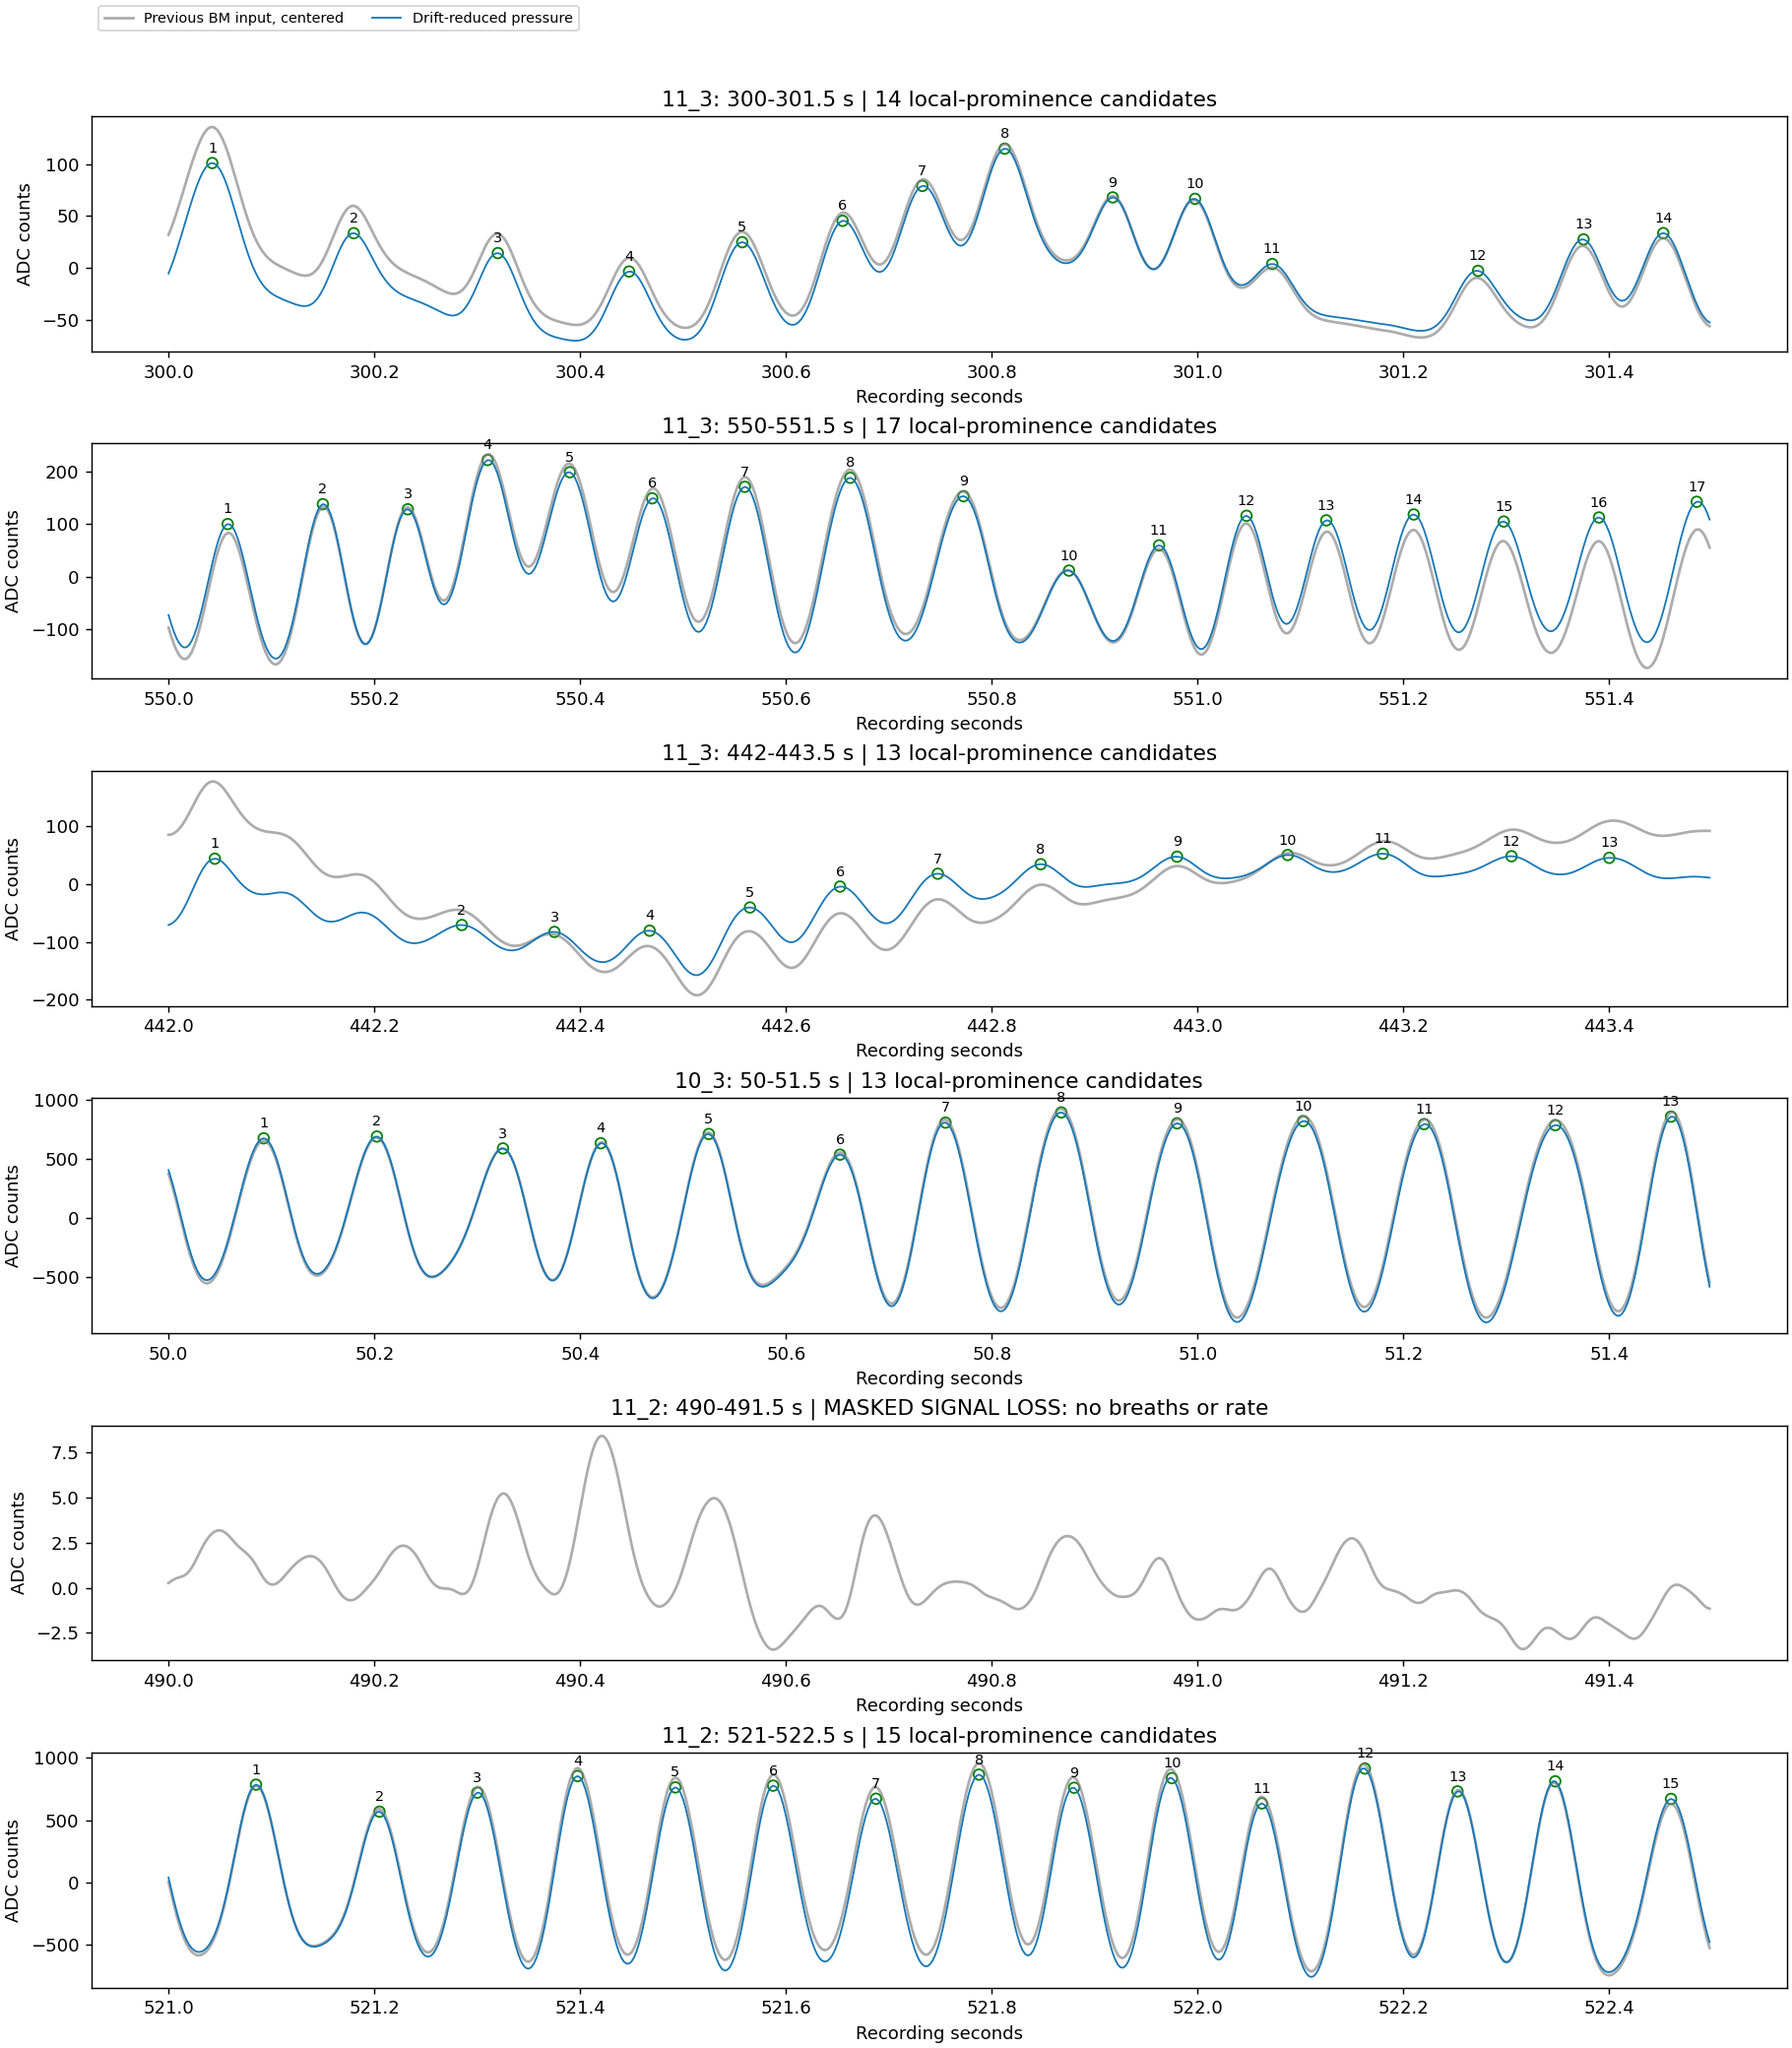

In [ ]:
from pathlib import Path
from IPython.display import Image, display
qc_dir = next(p for p in [Path.cwd(), Path.cwd()/'outputs/aim1_summer2026_ranked_recs'] if (p/'qc_local_prominence_fix.png').exists())
display(Image(filename=str(qc_dir/'qc_local_prominence_fix.png')))


## 11.3 rejection audit: do not interpret zero passing windows as unusable signal

The stored export rejected all 209 windows: 157 failed both the near-flat and minimum-breath checks, 51 failed the breath-count check alone, and one final partial window failed the count check. Only 18 candidate onsets were detected over the session; each window had at most one complete detected breath.

The near-flat peak-to-peak threshold is approximately 1001 ADC counts, derived from a session range of approximately 50044 ADC counts. Large transients inflate these session-wide metrics. The separate BreathMetrics detector also uses a session-wide amplitude threshold. The plots show visible cycles in several rejected intervals, including 50-53 and 550-553 s. Thus the existing exclusion is not evidence that all signal is bad. Detector sensitivity and artifact handling require revision before exclusion-based group results or the handoff are treated as final.

No thresholds, feature arrays or eligibility flags were changed by this audit. Plots show antialias-downsampled pressure versus detector input, not independently validated inhalation labels.


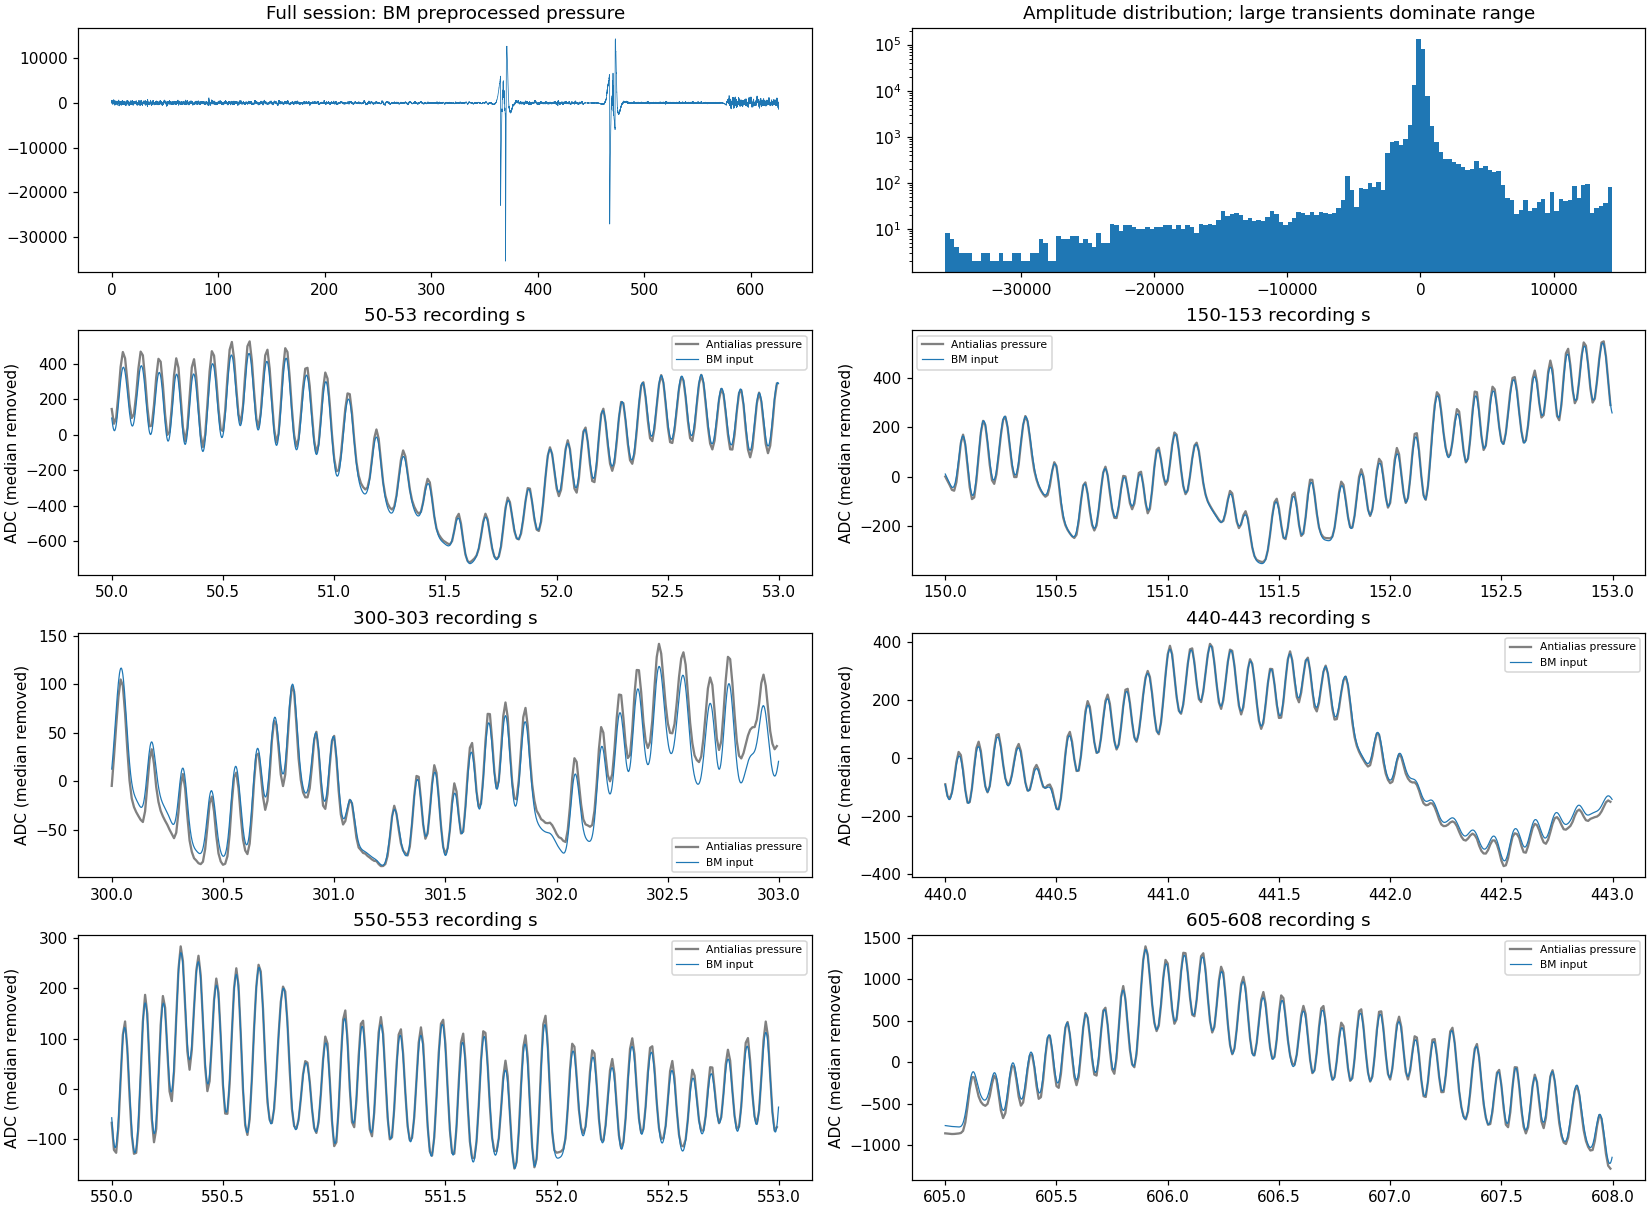

In [ ]:
# Saved 11.3 audit figure; see scripts/audit_11_3_screen.py to regenerate.
from IPython.display import display, Image
from pathlib import Path
audit_dir = next(p for p in [Path.cwd(), *[q/'outputs/aim1_summer2026_ranked_recs' for q in [Path.cwd(),*Path.cwd().parents]]] if (p/'qc_11_3_rejection_audit.png').exists())
display(Image(filename=str(audit_dir/'qc_11_3_rejection_audit.png')))

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from IPython.display import display
DATA_DIR = next(p for p in [Path.cwd(), *[q/'outputs/aim1_summer2026_ranked_recs' for q in [Path.cwd(),*Path.cwd().parents]]] if (p/'export_manifest.json').exists())
manifest=json.loads((DATA_DIR/'export_manifest.json').read_text())
tables=[]
for record in manifest:
    path=DATA_DIR/record['file']
    digest=hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda:f.read(4194304),b''): digest.update(chunk)
    assert digest.hexdigest()==record['sha256'], path.name
    with h5py.File(path,'r') as h:
        assert h.attrs['schema_version']=='2.0-thomas-screened'
        g=h['breathmetrics/windows']
        df=pd.DataFrame(g['X'][:],columns=g['feature_names'].asstr()[:])
        for key in ['start_s','stop_s','eligible_for_exploratory_model','manual_interval_approval']:
            df[key]=g[key][:]
        for key in ['phase','rejection_reason']:df[key]=g[key].asstr()[:]
        for key in ['session_id','subject_id','subject_rank','partner_id','partner_rank']:df[key]=h.attrs[key]
        tables.append(df)
windows=pd.concat(tables,ignore_index=True)
display(windows.groupby('session_id').agg(total_windows=('start_s','size'),eligible_windows=('eligible_for_exploratory_model','sum')))


,total_windows,eligible_windows
session_id,,
10_2_d_CM_10_1_s_20260729_114455,209,0
10_3_s_CM_10_2_d_20260729_174121,214,213
11_2_s_CM_11_4_d_20260729_172306,239,222
11_3_s_CM_11_4_d_20260729_122040,209,0
11_4_d_CM_11_3_s_20260729_125055,208,202
13_1_s_CM_13_2_d_20260729_170124,211,181
13_2_d_CM_13_1_s_20260729_111038,209,208
13_2_d_CM_13_1_s_20260729_181321,220,219
13_3_CM_s_13_2_d_20260729_175658,216,215


## What should Yongxu use?

Use `eligible_for_exploratory_model` plus finite values for the specific features your model needs. Excluded rows have NaN feature values and a reason. `manual_interval_approval` is false until interval review is explicitly recorded. Model train/test splits must group by mouse/cage, not randomly split adjacent windows. Never join retained pieces across gaps.

Thresholds are in each H5: three-second windows, at least four complete breaths, and both SD and peak-to-peak range at least 2% of session values (absolute floors apply). Feature statistics may still be undefined after a window passes. These are configured choices, not proof of clean signal or exact reproduction of every historical notebook.


In [2]:
required_features=['breathing_rate_hz','cv_ibi']
model_rows=windows.loc[windows.eligible_for_exploratory_model & np.isfinite(windows[required_features]).all(axis=1)].copy()
print('Windows passing automated eligibility and required-feature checks:',len(model_rows))
display(windows.loc[~windows.eligible_for_exploratory_model,['session_id','start_s','stop_s','rejection_reason']].head(30))


Windows passing automated eligibility and required-feature checks: 1666


,session_id,start_s,stop_s,rejection_reason
22,14_3_s_CM_14_1_d_20260729_112525,66.0,69.00000,fewer_than_4_complete_breaths
62,14_3_s_CM_14_1_d_20260729_112525,186.0,189.00000,fewer_than_4_complete_breaths
72,14_3_s_CM_14_1_d_20260729_112525,216.0,219.00000,fewer_than_4_complete_breaths
79,14_3_s_CM_14_1_d_20260729_112525,237.0,240.00000,fewer_than_4_complete_breaths
86,14_3_s_CM_14_1_d_20260729_112525,258.0,261.00000,fewer_than_4_complete_breaths
101,14_3_s_CM_14_1_d_20260729_112525,303.0,306.00000,fewer_than_4_complete_breaths
102,14_3_s_CM_14_1_d_20260729_112525,306.0,309.00000,fewer_than_4_complete_breaths
105,14_3_s_CM_14_1_d_20260729_112525,315.0,318.00000,fewer_than_4_complete_breaths
113,14_3_s_CM_14_1_d_20260729_112525,339.0,342.00000,fewer_than_4_complete_breaths
116,14_3_s_CM_14_1_d_20260729_112525,348.0,351.00000,fewer_than_4_complete_breaths


## Pressure, recording clock and BORIS

Raw signal and downsampled signal are unchanged. The BM processed signal is at nominal 400 Hz, with original recording-clock timestamps. Event timestamps remain in `/events`; fraction of each event covered by eligible windows is `/breathmetrics/boris_event_eligible_time_fraction`. Seven recordings lack detailed BORIS events. Coverage is not a per-event feature summary or proof of synchronization.


In [3]:
SESSION_ID='11_2_s_CM_11_4_d_20260729_172306'
with h5py.File(DATA_DIR/(SESSION_ID+'.h5'),'r') as h:
    recording_time=h['respiration/processed/time_s'][:]
    pressure=h['respiration/processed/pressure_downsampled'][:]
    print('Subject rank:',h.attrs['subject_rank'],'Partner rank:',h.attrs['partner_rank'])
    print('BORIS status:',h['events'].attrs['boris_status'])
    event_table=pd.DataFrame({'start_s':h['events/candidate_recording_start_s'][:], 'stop_s':h['events/candidate_recording_stop_s'][:], 'eligible_time_fraction':h['breathmetrics/boris_event_eligible_time_fraction'][:]})
    display(event_table.head())


Subject rank: 2 Partner rank: 1
BORIS status: No CSV found


,start_s,stop_s,eligible_time_fraction


## Baseline versus social, split by recorded mouse rank

Uses only eligible, finite **Thomas BreathMetrics breathing_rate_hz** values. Each session-phase mean is weighted by retained window duration. Comparisons require both phases. Repeated paired sessions for 13.2 are averaged within mouse; mice have equal weight. Boundary-straddling windows are omitted.

These are descriptive comparisons, not evidence that rank causes a difference. Cage mates/reciprocal partners are dependent, sample sizes are small, exclusions differ by phase, and phase alignment/manual QC remain provisional. Numeric rank is the recorded mouse's rank from notes, not a binary dominant/subordinate label. Rates are averages of window summaries, not a pooled breath count. The 80% coverage sensitivity is exploratory, not an established validity cutoff.


7 paired mice from 4 cages; 8 paired recordings.
Mean paired change (Hz): 0.12943828410717106
Missing a phase:
Sensitivity (>=80% retained per phase): 6 mice; mean change 0.06603005505843666 Hz
No rank p-values: small rank groups and shared cages/partners do not support treating windows as independent samples.


,subject_id,session_id,phase,retained_s,phase_duration_s,retained_fraction,mean_rate_hz
0,14.3,14_3_s_CM_14_1_d_20260729_112525,baseline,291.0,320.024166,0.909306,4.529401
1,14.3,14_3_s_CM_14_1_d_20260729_112525,social,285.0,306.042283,0.931244,4.650714
2,14.1,14_1_d_CM_14_3_s_20260729_120334,baseline,36.0,315.043122,0.114270,3.033753
3,14.1,14_1_d_CM_14_3_s_20260729_120334,social,0.0,309.013906,0.000000,NaN
4,13.3,13_3_CM_s_13_2_d_20260729_175658,baseline,309.0,314.002483,0.984069,8.307063
5,13.3,13_3_CM_s_13_2_d_20260729_175658,social,330.0,331.050510,0.996827,8.544215
6,13.2,13_2_d_CM_13_1_s_20260729_181321,baseline,333.0,335.065697,0.993835,6.175477
7,13.2,13_2_d_CM_13_1_s_20260729_181321,social,321.0,321.975011,0.996972,7.380583
8,13.2,13_2_d_CM_13_1_s_20260729_111038,baseline,315.0,315.805370,0.997450,6.947325
9,13.2,13_2_d_CM_13_1_s_20260729_111038,social,306.0,308.251592,0.992696,6.358376


,rank,n_mice,baseline_hz,social_hz,change_hz
0,1,2,7.024038,7.213071,0.189034
1,2,1,7.704626,7.744376,0.039750
2,3,2,8.264904,8.193430,-0.071474
3,4,2,5.088034,5.403634,0.315600


phase,subject_id,session_id,baseline,social
0,10.2,10_2_d_CM_10_1_s_20260729_114455,NaN,NaN
3,11.3,11_3_s_CM_11_4_d_20260729_122040,NaN,NaN
9,14.1,14_1_d_CM_14_3_s_20260729_120334,3.033753,NaN


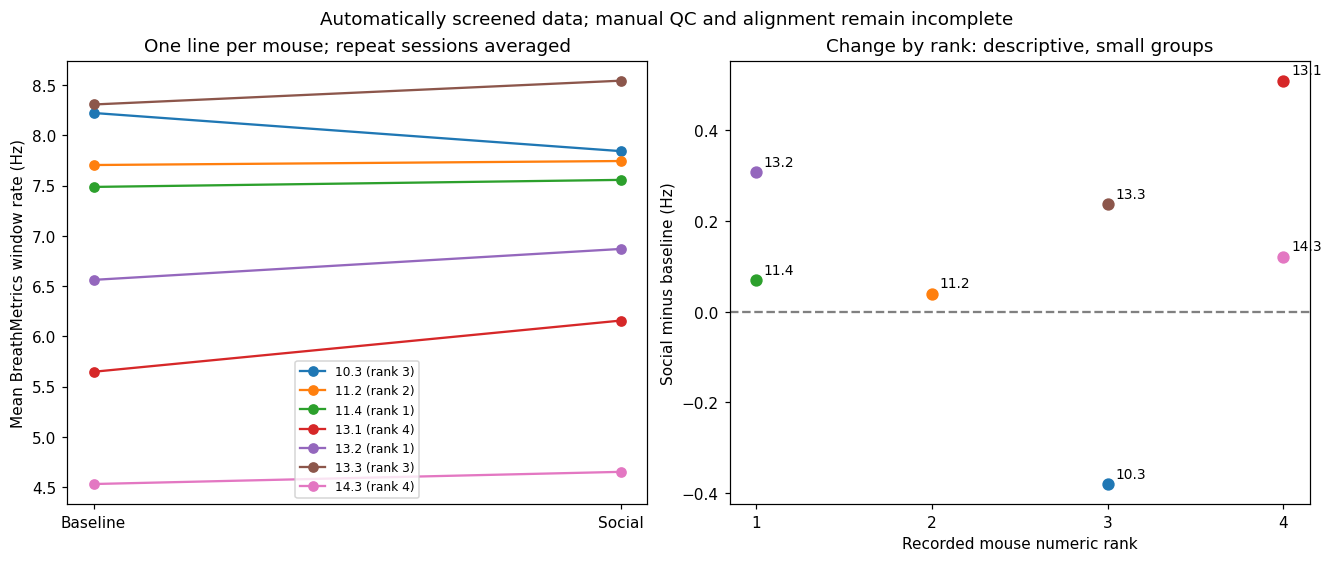

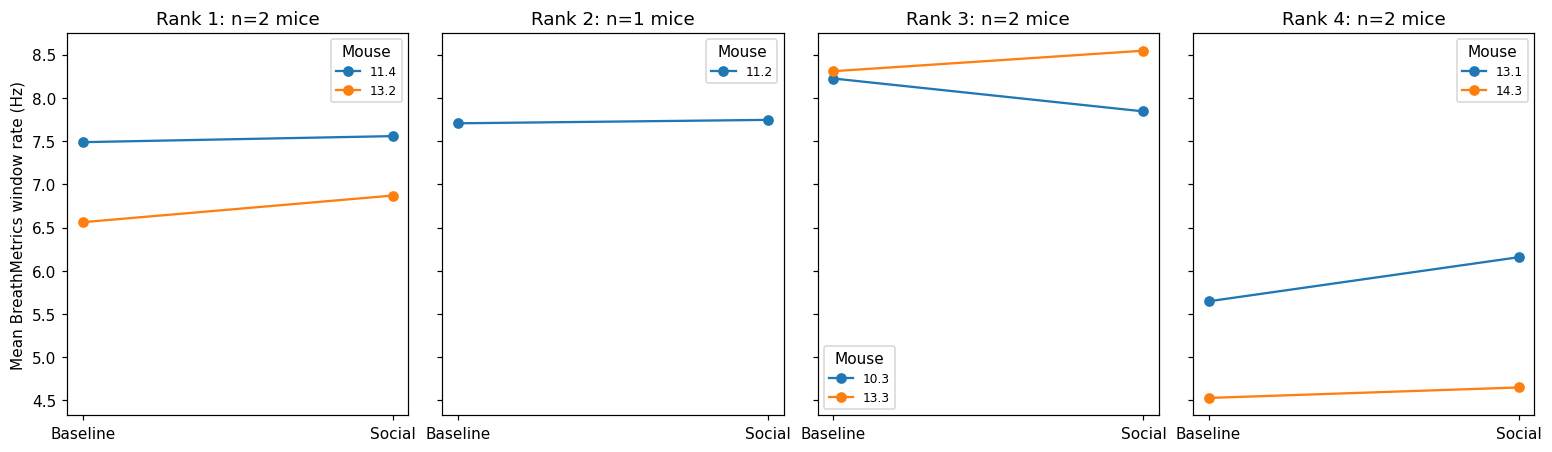

In [ ]:
# Compare eligible BreathMetrics rate windows, not the legacy detector.
phase_rows=[]
for record in manifest:
    with h5py.File(DATA_DIR/record['file'],'r') as h:
        g=h['breathmetrics/windows']; names=list(g['feature_names'].asstr()[:])
        rate=g['X'][:,names.index('breathing_rate_hz')] if 'breathing_rate_hz' in names else np.full(len(g['start_s']),np.nan)
        starts=g['start_s'][:]; stops=g['stop_s'][:]; phase=g['phase'].asstr()[:]
        good=g['eligible_for_exploratory_model'][:]&np.isfinite(rate)
        bounds=h['candidate_recording_boundaries_s'][:]
        for label,lo,hi in [('baseline',bounds[0],bounds[1]),('social',bounds[1],bounds[2])]:
            use=good&(phase==label); seconds=float(np.sum((stops-starts)[use]))
            phase_rows.append(dict(session_id=h.attrs['session_id'],subject_id=h.attrs['subject_id'],rank=int(h.attrs['subject_rank']),partner_rank=int(h.attrs['partner_rank']),cage_id=str(h.attrs['cage_id']),phase=label,retained_s=seconds,phase_duration_s=hi-lo,retained_fraction=seconds/(hi-lo),n_windows=int(use.sum()),mean_rate_hz=float(np.average(rate[use],weights=(stops-starts)[use])) if use.any() else np.nan))
phase_summary=pd.DataFrame(phase_rows)
session_pairs=phase_summary.pivot(index=['session_id','subject_id','rank','cage_id'],columns='phase',values='mean_rate_hz').reset_index()
session_pairs['paired']=session_pairs[['baseline','social']].notna().all(axis=1)
# Equal-weight repeated paired sessions within each mouse; never count 13.2 twice.
mouse_pairs=session_pairs[session_pairs.paired].groupby(['subject_id','rank','cage_id'],as_index=False)[['baseline','social']].mean()
mouse_pairs['social_minus_baseline_hz']=mouse_pairs.social-mouse_pairs.baseline
rank_summary=mouse_pairs.groupby('rank').agg(n_mice=('subject_id','size'),baseline_hz=('baseline','mean'),social_hz=('social','mean'),change_hz=('social_minus_baseline_hz','mean')).reset_index()
print(f'{len(mouse_pairs)} paired mice from {mouse_pairs.cage_id.nunique()} cages; {session_pairs.paired.sum()} paired recordings.')
print('Mean paired change (Hz):',mouse_pairs.social_minus_baseline_hz.mean())
display(phase_summary[['subject_id','session_id','phase','retained_s','phase_duration_s','retained_fraction','mean_rate_hz']])
display(rank_summary)
print('Missing a phase:')
display(session_pairs.loc[~session_pairs.paired,['subject_id','session_id','baseline','social']])
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for row in mouse_pairs.itertuples():
    axes[0].plot([0,1],[row.baseline,row.social],marker='o',label=f'{row.subject_id} (rank {row.rank})')
    axes[1].scatter(row.rank,row.social_minus_baseline_hz,s=50)
    axes[1].annotate(row.subject_id,(row.rank,row.social_minus_baseline_hz),xytext=(5,4),textcoords='offset points',fontsize=9)
axes[0].set(xticks=[0,1],xticklabels=['Baseline','Social'],ylabel='Mean BreathMetrics window rate (Hz)',title='One line per mouse; repeat sessions averaged')
axes[0].legend(fontsize=8)
axes[1].axhline(0,color='gray',ls='--');axes[1].set(xticks=[1,2,3,4],xlabel='Recorded mouse numeric rank',ylabel='Social minus baseline (Hz)',title='Change by rank: descriptive, small groups')
fig.suptitle('Automatically screened data; manual QC and alignment remain incomplete')
plt.show()
fig,axes=plt.subplots(1,4,figsize=(14,4),sharey=True,layout='constrained')
for rank,ax in zip([1,2,3,4],axes):
    group=mouse_pairs[mouse_pairs['rank']==rank]
    for row in group.itertuples():ax.plot([0,1],[row.baseline,row.social],marker='o',label=row.subject_id)
    ax.set(xticks=[0,1],xticklabels=['Baseline','Social'],title=f'Rank {rank}: n={len(group)} mice')
    if len(group):ax.legend(title='Mouse',fontsize=8)
axes[0].set_ylabel('Mean BreathMetrics window rate (Hz)')
plt.show()
# Sensitivity: require at least 80% retained time in BOTH phases (exploratory).
coverage_pairs=phase_summary.pivot(index='session_id',columns='phase',values='retained_fraction')
covered=coverage_pairs.index[(coverage_pairs.baseline>=.8)&(coverage_pairs.social>=.8)]
sensitivity=session_pairs[session_pairs.paired & session_pairs.session_id.isin(covered)].groupby(['subject_id','rank'],as_index=False)[['baseline','social']].mean()
sensitivity['change_hz']=sensitivity.social-sensitivity.baseline
print('Sensitivity (>=80% retained per phase):',len(sensitivity),'mice; mean change',sensitivity.change_hz.mean(),'Hz')
print('No rank p-values: small rank groups and shared cages/partners do not support treating windows as independent samples.')


## Optional whole-session pressure review

The following is the existing minute-by-minute view. Its green markers are the LEGACY detector, not the new BreathMetrics onsets. Use raw pressure for quality inspection; no automatic approval is recorded by displaying it.


## Review the whole session, minute by minute

Choose `REVIEW_SESSION` below and run this cell **once**. All minutes appear in chronological order; scroll down to review the entire session. Each minute has six consecutive 10-second rows; the final minute may be shorter. No minute-number changes or repeated runs are needed.

Gray: raw min/max envelope in 1-ms bins. Blue: antialias-downsampled pressure. Green: existing candidate peaks, not approved breaths. Pressure offsets and original recording times are preserved. Vertical scale is shared within each minute, not across the entire session; use axis values when comparing amplitudes. Set `SHARED_VERTICAL_SCALE = False` if a transient hides smaller cycles.

Note questionable start/stop recording seconds for the review-notes section. This view does not exclude data, approve intervals, or change BORIS alignment.


In [ ]:
# Choose a session and run once to display ALL its minutes in order.
REVIEW_SESSION = '10_2_d_CM_10_1_s_20260729_114455'
SHARED_VERTICAL_SCALE = True  # False enlarges weak signals in each row.

with h5py.File(DATA_DIR/(REVIEW_SESSION+'.h5'),'r') as h:
    fs = float(h.attrs['clock_rate_hz'])
    origin = int(h.attrs['recording_tick_origin'])
    ticks = h['respiration/raw/acquisition_ticks'][:]
    end = float((int(ticks[-1])-origin)/fs)
    total_minutes = int(np.ceil(end/60))
    for MINUTE_NUMBER in range(1,total_minutes+1):
        start = (MINUTE_NUMBER-1)*60.0
        stop = min(start+60,end)
        t = h['respiration/processed/time_s'][:]
        pressure = h['respiration/processed/pressure_downsampled'][:]
        peaks = h['respiration/candidate_breaths/peak_time_s'][:]
        boundaries = h['candidate_recording_boundaries_s'][:]
        nrows = int(np.ceil((stop-start)/10))
        fig,axes = plt.subplots(nrows,1,figsize=(15,2.4*nrows),sharey=SHARED_VERTICAL_SCALE,squeeze=False,layout='constrained')
        for row,ax in enumerate(axes[:,0]):
            lo = start+row*10
            hi = min(lo+10,stop)
            left,right = np.searchsorted(ticks,[origin+lo*fs,origin+hi*fs],side='left')
            raw = h['respiration/raw/pressure_adc'][left:right].astype(float)
            rt = (ticks[left:right].astype(float)-origin)/fs
            # Show raw extrema in 1-ms bins, rather than skipping isolated spikes.
            block_size = max(1,int(round(fs/1000)))
            count = len(raw)//block_size
            if count:
                values = raw[:count*block_size].reshape(count,block_size)
                bt = rt[:count*block_size].reshape(count,block_size).mean(axis=1)
                ax.fill_between(bt,values.min(axis=1),values.max(axis=1),color='gray',alpha=.45,label='Raw min/max envelope (1 ms)')
            mask = (t>=lo)&(t<=hi)
            ax.plot(t[mask],pressure[mask],color='#167fa0',lw=.9,label='Downsampled pressure (antialias only)')
            pp = peaks[(peaks>=lo)&(peaks<hi)]
            if mask.any():
                ax.scatter(pp,np.interp(pp,t[mask],pressure[mask]),s=20,facecolors='none',edgecolors='green',label='Candidate peaks, not approved')
            for bound in boundaries[1:]:
                if lo<=bound<=hi: ax.axvline(bound,color='#ba6945',ls='--')
            ax.set(xlim=(lo,hi),ylabel='ADC counts',title=f'{lo:.0f}-{hi:.2f} recording seconds')
            ax.set_xticks(np.arange(lo,hi+.001,1))
            ax.grid(axis='x',alpha=.2)
        axes[0,0].legend(fontsize=8,loc='upper right')
        axes[-1,0].set_xlabel('Recording-clock seconds; original pressure offset preserved')
        fig.suptitle(f'{REVIEW_SESSION} | minute {MINUTE_NUMBER}/{total_minutes} | raw-pressure QC')
        plt.show()
        print(f'Reviewed display: {start:.1f}-{stop:.2f} s. Displaying is not approval.')
print('Entire session displayed. Record decisions before changing REVIEW_SESSION; displaying does not approve data.')
